### **04_TIDIGITS — PRML Assignment 8**

Comparing LDA, KNN, SVM (78-dim summary) and GMM (sequential frames) on TIDIGITS (Digits 3, 7, 9).


### **Imports**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from src import LDA, KNN, SVM, FrameGMM, PCA, StandardScaler, SpeechSummary, LCG


### **Load and Split TIDIGITS Recordings**

In [2]:
data_dir = "../Datasets/TIDIGITS"

sequences, labels = [], []
for digit in (3, 7, 9):
    with np.load(f"{data_dir}/{digit}.npz") as archive:
        for key in sorted(archive.files):
            sequences.append(np.asarray(archive[key], dtype=float))
            labels.append(digit)
labels = np.asarray(labels)

# Stratified split: 60% train, 20% validation, 20% test per digit using LCG
lcg = LCG(seed=42)
train_ids, val_ids, test_ids = [], [], []
for digit in np.unique(labels):
    ids = lcg.permutation(np.flatnonzero(labels == digit))
    a, b = int(0.6 * len(ids)), int(0.8 * len(ids))
    train_ids.extend(ids[:a])
    val_ids.extend(ids[a:b])
    test_ids.extend(ids[b:])

train_seq = [sequences[i] for i in train_ids]
val_seq = [sequences[i] for i in val_ids]
test_seq = [sequences[i] for i in test_ids]
y_train, y_val, y_test = labels[train_ids], labels[val_ids], labels[test_ids]

print("Recordings — Train:", len(train_seq), "Validation:", len(val_seq), "Test:", len(test_seq))

# Setup classes and results dictionary for evaluation
classes = np.unique(y_train)
label_to_idx = {int(c): i for i, c in enumerate(classes)}
results = {}

Recordings — Train: 810 Validation: 270 Test: 270


### **Part A: Fixed-Length Summary Features (78 Dimensions)**

In [3]:
X_train = SpeechSummary.transform(train_seq)
X_val = SpeechSummary.transform(val_seq)
X_test = SpeechSummary.transform(test_seq)

summary_scaler = StandardScaler().fit(X_train)
X_train_s = summary_scaler.transform(X_train)
X_val_s = summary_scaler.transform(X_val)
X_test_s = summary_scaler.transform(X_test)
print("Summary feature shape:", X_train_s.shape)

Summary feature shape: (810, 78)


### **LDA, KNN, and SVM on Original Summaries**


### **1. LDA on Original Summaries**


In [4]:
# Train and evaluate LDA on original summary features
lda = LDA()
lda.fit(X_train_s, y_train)

val_pred = lda.predict(X_val_s)
test_pred = lda.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["LDA original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"LDA original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

LDA original     | Validation: 0.3370 | Test: 0.3778
Confusion matrix:
 [[36 17 37]
 [29 35 26]
 [30 29 31]]


### **2. KNN on Original Summaries**


In [5]:
# Train and evaluate KNN on original summary features
knn = KNN(k=5)
knn.fit(X_train_s, y_train)

val_pred = knn.predict(X_val_s)
test_pred = knn.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["KNN original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"KNN original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

KNN original     | Validation: 0.3296 | Test: 0.2889
Confusion matrix:
 [[51 30  9]
 [62 22  6]
 [55 30  5]]


### **3. SVM on Original Summaries**


In [6]:
# Train and evaluate SVM on original summary features
svm = SVM(kernel="rbf", C=1.0, max_train=1000)
svm.fit(X_train_s, y_train)

val_pred = svm.predict(X_val_s)
test_pred = svm.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["SVM original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"SVM original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

SVM original     | Validation: 0.3593 | Test: 0.3926
Confusion matrix:
 [[30 26 34]
 [27 36 27]
 [25 25 40]]


### **PCA on Summary Features**

In [7]:
summary_pca = PCA(n_components=20).fit(X_train_s)
X_train_p = summary_pca.transform(X_train_s)
X_val_p = summary_pca.transform(X_val_s)
X_test_p = summary_pca.transform(X_test_s)
print("Summary PCA retained variance:", round(float(summary_pca.explained_variance_ratio_.sum()), 4))

Summary PCA retained variance: 0.3677


### **LDA, KNN, and SVM on PCA Summaries**


### **1. LDA on PCA Summaries**


In [8]:
# Train and evaluate LDA on PCA summary features
lda_p = LDA()
lda_p.fit(X_train_p, y_train)

val_pred = lda_p.predict(X_val_p)
test_pred = lda_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["LDA PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"LDA PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

LDA PCA          | Validation: 0.3296 | Test: 0.3111
Confusion matrix:
 [[29 24 37]
 [28 26 36]
 [36 25 29]]


### **2. KNN on PCA Summaries**


In [9]:
# Train and evaluate KNN on PCA summary features
knn_p = KNN(k=5)
knn_p.fit(X_train_p, y_train)

val_pred = knn_p.predict(X_val_p)
test_pred = knn_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["KNN PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"KNN PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

KNN PCA          | Validation: 0.3519 | Test: 0.3296
Confusion matrix:
 [[44 33 13]
 [48 32 10]
 [48 29 13]]


### **3. SVM on PCA Summaries**


In [10]:
# Train and evaluate SVM on PCA summary features
svm_p = SVM(kernel="rbf", C=1.0, max_train=1000)
svm_p.fit(X_train_p, y_train)

val_pred = svm_p.predict(X_val_p)
test_pred = svm_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["SVM PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"SVM PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

SVM PCA          | Validation: 0.3185 | Test: 0.3259
Confusion matrix:
 [[27 33 30]
 [29 32 29]
 [35 26 29]]


### **Part B: Sequential Frame Features (GMM)**


In [11]:
frame_scaler = StandardScaler().fit(np.concatenate(train_seq))
train_frames = [frame_scaler.transform(s) for s in train_seq]
val_frames = [frame_scaler.transform(s) for s in val_seq]
test_frames = [frame_scaler.transform(s) for s in test_seq]

### **GMM on Original Frames**


In [12]:
# Train and evaluate FrameGMM on original frames
gmm = FrameGMM(K=3, reg=1e-3, max_iter=80)
gmm.fit(train_frames, y_train)

val_pred = gmm.predict(val_frames)
test_pred = gmm.predict(test_frames)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["GMM original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"GMM original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

GMM original     | Validation: 0.9926 | Test: 0.9889
Confusion matrix:
 [[89  1  0]
 [ 0 90  0]
 [ 2  0 88]]


### **PCA on Frame Features**

In [13]:
frame_pca = PCA(n_components=15).fit(np.concatenate(train_frames))
train_frames_p = [frame_pca.transform(s) for s in train_frames]
val_frames_p = [frame_pca.transform(s) for s in val_frames]
test_frames_p = [frame_pca.transform(s) for s in test_frames]
print("Frame PCA retained variance:", round(float(frame_pca.explained_variance_ratio_.sum()), 4))

Frame PCA retained variance: 0.6781


### **GMM on PCA Frames**


In [14]:
# Train and evaluate FrameGMM on PCA frames
gmm_p = FrameGMM(K=3, reg=1e-3, max_iter=80)
gmm_p.fit(train_frames_p, y_train)

val_pred = gmm_p.predict(val_frames_p)
test_pred = gmm_p.predict(test_frames_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["GMM PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"GMM PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

GMM PCA          | Validation: 0.9926 | Test: 0.9889
Confusion matrix:
 [[89  1  0]
 [ 0 90  0]
 [ 1  1 88]]


### **Results Comparison**

LDA original     | Validation: 0.3370 | Test: 0.3778
KNN original     | Validation: 0.3296 | Test: 0.2889
SVM original     | Validation: 0.3593 | Test: 0.3926
LDA PCA          | Validation: 0.3296 | Test: 0.3111
KNN PCA          | Validation: 0.3519 | Test: 0.3296
SVM PCA          | Validation: 0.3185 | Test: 0.3259
GMM original     | Validation: 0.9926 | Test: 0.9889
GMM PCA          | Validation: 0.9926 | Test: 0.9889


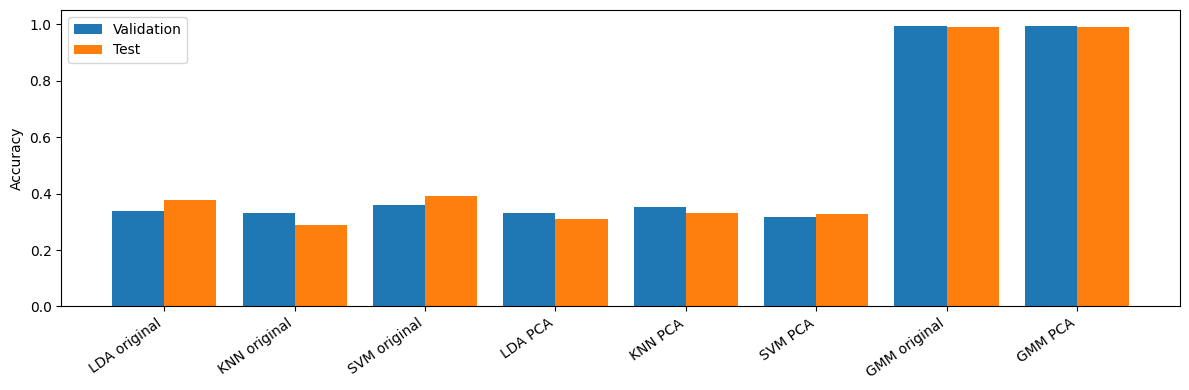

In [15]:
for name, (val_acc, test_acc) in results.items():
    print(f"{name:16s} | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")

names = list(results.keys())
x_pos = np.arange(len(names))

plt.figure(figsize=(12, 4))
plt.bar(x_pos - 0.2, [results[n][0] for n in names], width=0.4, label="Validation")
plt.bar(x_pos + 0.2, [results[n][1] for n in names], width=0.4, label="Test")
plt.xticks(x_pos, names, rotation=35, ha="right")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

### **Observations and Inferences**

- Frame-based GMM evaluates full sequences of spectral frames and achieves strong performance because it captures the distribution of spectral frames across time.
- Summary features (mean and std) collapse temporal dynamics, which lowers accuracy compared to sequence-level modeling.
